# CNNs and the multimodal fusion model

Do spatial neighbourhoods help beyond the pixel baselines (`02_baselines`), and does fusing hyperspectral and thermal
information beat each modality alone? This is the main deep learning experiment of the project (slides 10–12).

| Model | Inputs | Role |
|---|---|---|
| `landsat_cnn` | Landsat bands + indices, elevation, slope, built-up share | multispectral reference |
| `spectral_cnn` | + 122 hyperspectral bands | spectral CNN |
| `thermal_cnn` | thermal context (median LST of other dates) | thermal CNN |
| `fusion_cnn` | both branches, feature maps concatenated | multimodal fusion |

All are fully convolutional (1×1 spectral reduction, then dilated residual blocks; receptive field 29 px ≈ 1.7 km),
predict the **LST anomaly** for every pixel, and get the sensor as an embedding. Thermal context and elevation are
given relative to the scene median, like the target. Training: random 32 × 32 patches with flips/rotations, masked
MSE, AdamW, mixed precision, early stopping on val. **Evaluation: every valid pixel of every test city** (whole
scenes), the same pixels for the XGBoost models, so the comparison is fair.

In [1]:
import json, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, xgboost as xgb
from pathlib import Path
from urbanheat.config import load_config
from urbanheat.data.dataset import PatchDataset
from urbanheat.models import cnn, train as T, features as F, baselines as B

cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])
plt.rcParams["figure.dpi"] = 90
torch.manual_seed(0); np.random.seed(0)

ds = {s: PatchDataset(H5, s) for s in ["train", "val", "test"]}
with h5py.File(H5) as f:
    info_of = {k: dict(climate_group=g.attrs["climate_group"], sensor=g.attrs["sensor"]) for k, g in f["pairs"].items()}
print({s: f"{len(d):,} patches / {len(d.pairs)} scenes" for s, d in ds.items()}, "|", torch.cuda.get_device_name(0))

{'train': '11,621 patches / 321 scenes', 'val': '561 patches / 45 scenes', 'test': '617 patches / 56 scenes'} | NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Train the four CNNs

In [2]:
TRAIN = dict(epochs=30, batch_size=32, lr=2e-3, samples_per_epoch=4000, patience=6)
results, models, histories = {}, {}, {}
for v in cnn.VARIANTS:
    print(f"--- {v}")
    torch.manual_seed(0)
    m = cnn.HeatCNN(v)
    histories[v] = T.fit(m, ds["train"], ds["val"], log=lambda s: None, **TRAIN)
    ev = {s: T.evaluate_scenes(m, ds[s], info_of)[0] for s in ["val", "test"]}
    eff = T.efficiency(m, ds["val"])
    results[v] = dict(run_id=f"cnn_anom_{v}", model=v, target="anomaly", **ev, **eff,
                      epochs=len(histories[v]), hardware=torch.cuda.get_device_name(0))
    T.save(m, RUNS / f"cnn_anom_{v}", results[v], histories[v], dict(variant=v, **TRAIN))
    models[v] = m
    print(f"{len(histories[v])} epochs | test MAE {ev['test']['mae']:.2f}  RMSE {ev['test']['rmse']:.2f}  R2 {ev['test']['r2']:.3f}"
          f" | {eff['params']:,} params, {eff['flops'] / 1e6:.0f} MFLOPs/patch")

--- landsat_cnn


C:\miniforge3\envs\pygile\lib\site-packages\torch\optim\lr_scheduler.py:224: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


27 epochs | test MAE 1.67  RMSE 2.28  R2 0.418 | 227,609 params, 464 MFLOPs/patch
--- spectral_cnn


27 epochs | test MAE 1.66  RMSE 2.32  R2 0.396 | 235,417 params, 480 MFLOPs/patch
--- thermal_cnn


20 epochs | test MAE 1.03  RMSE 1.52  R2 0.742 | 58,489 params, 119 MFLOPs/patch
--- fusion_cnn


30 epochs | test MAE 1.00  RMSE 1.42  R2 0.775 | 293,241 params, 598 MFLOPs/patch


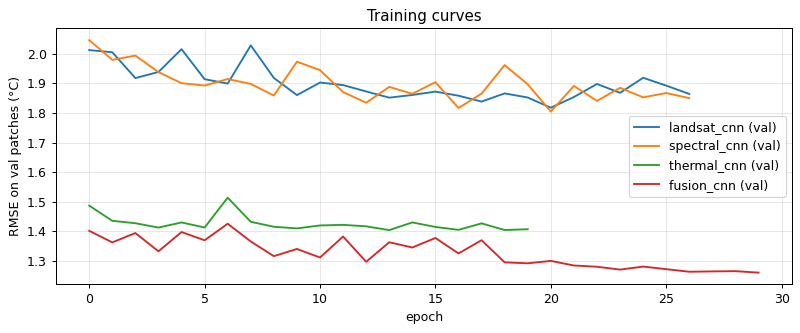

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for v, h in histories.items():
    ax.plot([e["val_rmse"] for e in h], label=f"{v} (val)")
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE on val patches (°C)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Training curves"); plt.tight_layout(); plt.show()

## XGBoost on exactly the same test pixels

The XGBoost models from `02_baselines` (trained on the pixel table) predict every valid pixel of the same test
scenes.

In [4]:
XGB = {"landsat": "landsat_cnn", "landsat+hs_bands": "spectral_cnn", "thermal_only": "thermal_cnn", "all": "fusion_cnn"}
sets = F.feature_sets([f"hs_{w:.0f}" for w in ds["test"].wavelengths])
xres = {}
for name in XGB:
    booster = xgb.XGBRegressor(); booster.load_model(RUNS / f"xgb_anom_{name}" / "model.json")
    ys, ps, cl, se = [], [], [], []
    for pid in ds["test"].pairs:
        Xp, yp, _ = F.pair_table(H5, pid)
        ys.append(yp); ps.append(booster.predict(Xp[sets[name]]))
        cl.append(np.full(len(yp), info_of[pid]["climate_group"])); se.append(np.full(len(yp), info_of[pid]["sensor"]))
    xres[name] = B.evaluate(np.concatenate(ys), np.concatenate(ps), pd.DataFrame({"climate_group": np.concatenate(cl), "sensor": np.concatenate(se)}))
    print(f"xgb {name:18s} test R2 {xres[name]['r2']:.3f}  MAE {xres[name]['mae']:.2f}  (n={xres[name]['n']:,})")

xgb landsat            test R2 0.261  MAE 1.91  (n=748,055)


xgb landsat+hs_bands   test R2 0.285  MAE 1.86  (n=748,055)


xgb thermal_only       test R2 0.740  MAE 1.03  (n=748,055)


xgb all                test R2 0.754  MAE 1.04  (n=748,055)


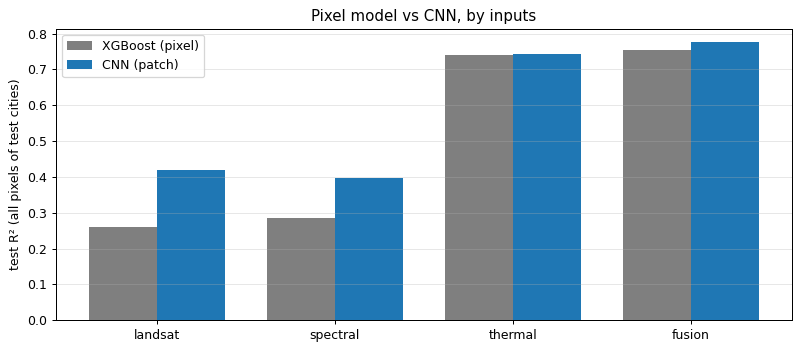

,inputs,model,test_r2,test_mae,test_rmse,params,mflops_per_patch,latency_ms_per_patch
0,landsat,XGBoost (pixel),0.261,1.908,2.571,NaN,NaN,NaN
1,landsat,CNN (patch),0.418,1.665,2.281,227609.0,464.126,0.340
2,spectral,XGBoost (pixel),0.285,1.864,2.530,NaN,NaN,NaN
3,spectral,CNN (patch),0.396,1.662,2.325,235417.0,480.117,0.350
4,thermal,XGBoost (pixel),0.740,1.033,1.525,NaN,NaN,NaN
5,thermal,CNN (patch),0.742,1.034,1.521,58489.0,118.686,0.290
6,fusion,XGBoost (pixel),0.754,1.035,1.485,NaN,NaN,NaN
7,fusion,CNN (patch),0.775,0.997,1.418,293241.0,597.623,0.423


In [5]:
rows = []
for name, v in XGB.items():
    rows.append(dict(inputs=v.replace("_cnn", ""), model="XGBoost (pixel)", test_r2=xres[name]["r2"], test_mae=xres[name]["mae"],
                     test_rmse=xres[name]["rmse"], params=None, mflops_per_patch=None, latency_ms_per_patch=None))
    r = results[v]
    rows.append(dict(inputs=v.replace("_cnn", ""), model="CNN (patch)", test_r2=r["test"]["r2"], test_mae=r["test"]["mae"],
                     test_rmse=r["test"]["rmse"], params=r["params"], mflops_per_patch=r["flops"] / 1e6,
                     latency_ms_per_patch=r["latency_ms"]))
comp = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4))
for i, (mod, col) in enumerate([("XGBoost (pixel)", "tab:gray"), ("CNN (patch)", "tab:blue")]):
    d = comp[comp.model == mod]
    ax.bar(np.arange(len(d)) + (i - 0.5) * 0.38, d.test_r2, width=0.38, label=mod, color=col)
ax.set_xticks(range(len(XGB))); ax.set_xticklabels(comp.inputs.unique()); ax.set_ylabel("test R² (all pixels of test cities)")
ax.set_title("Pixel model vs CNN, by inputs"); ax.legend(); ax.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()
comp.round(3)

In [6]:
pd.DataFrame({v: {g: s["r2"] for g, s in r["test"]["per_climate"].items()} for v, r in results.items()}).T.round(3)

,arid,cold,temperate,tropical
landsat_cnn,0.294,0.216,0.593,0.420
spectral_cnn,0.313,0.256,0.585,0.386
thermal_cnn,0.640,0.383,0.843,0.758
fusion_cnn,0.626,0.379,0.922,0.795


## A test city: observed vs models

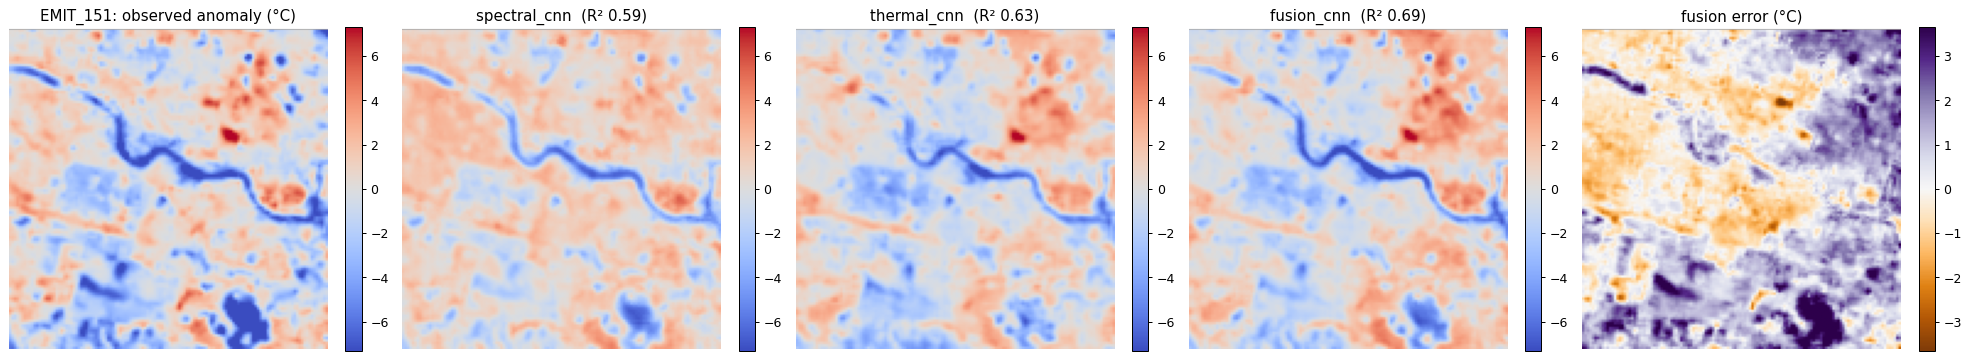

In [7]:
pid = max(ds["test"].pairs, key=lambda p: T.predict_scene(models["fusion_cnn"], ds["test"], p)[2].sum())
maps = {v: T.predict_scene(models[v], ds["test"], pid) for v in ["spectral_cnn", "thermal_cnn", "fusion_cnn"]}
_, y, m = maps["fusion_cnn"]
lim = np.nanpercentile(np.abs(y[m]), 98)
fig, ax = plt.subplots(1, 5, figsize=(22, 4.4))
show = lambda a, img, t, cmap="coolwarm", l=lim: (plt.colorbar(a.imshow(np.where(m, img, np.nan), cmap=cmap, vmin=-l, vmax=l), ax=a, fraction=0.046), a.set_title(t), a.axis("off"))
show(ax[0], y, f"{pid}: observed anomaly (°C)")
for a, v in zip(ax[1:4], ["spectral_cnn", "thermal_cnn", "fusion_cnn"]):
    p = maps[v][0]; show(a, p, f"{v}  (R² {B.scores(y[m], p[m])['r2']:.2f})")
show(ax[4], maps["fusion_cnn"][0] - y, "fusion error (°C)", "PuOr", lim / 2)
plt.tight_layout(); plt.show()

## Summary (every valid pixel of the 56 test cities, 748 k pixels)

| Inputs | XGBoost (pixel) R² | CNN (patch) R² | CNN MAE (°C) | CNN params | MFLOPs / patch |
|---|---|---|---|---|---|
| Landsat + terrain + built-up | 0.26 | **0.42** | 1.67 | 228 k | 464 |
| + 122 hyperspectral bands | 0.29 | 0.40 | 1.66 | 235 k | 480 |
| thermal context | 0.74 | 0.74 | 1.03 | 58 k | 119 |
| **fusion (all)** | 0.75 | **0.78** | **1.00** | 293 k | 598 |

1. **The multimodal fusion CNN is the best model** (R² 0.78, MAE 1.0 °C), better than the thermal CNN alone
   (0.74) and the best pixel model (0.75). Fusing surface and thermal information helps, as the project proposed.
2. **Spatial neighbourhood matters a lot for the surface inputs**: the Landsat CNN beats the Landsat pixel model by
   +0.16 R² (0.26 → 0.42). What surrounds a pixel (a park next to it, dense blocks around it) changes its temperature.
3. **Hyperspectral bands did not help the CNN on their own** (0.40 vs 0.42): with 122 correlated bands and 321
   training scenes the spectral branch overfits a little. Spectral reduction (PCA / band selection, Member 3) is
   the obvious next test.
4. The fusion model was still improving at epoch 30 (training curve), so longer training may add a little.
5. All models smooth the extremes: very cold water bodies and the hottest spots are under-predicted (error map).
6. Cold-climate cities stay hardest (R² ≈ 0.38); temperate ≈ 0.92, tropical ≈ 0.80.

**Hand-over:** `runs/cnn_anom_fusion_cnn/` (model.pt, metrics.json, config) is the **Member 2 model** for Member 3
(teacher for distillation; 293 k params, 0.6 GFLOPs per 32×32 patch, 0.42 ms per patch on an RTX 3050 laptop GPU)
and for Member 4 (predictions and explanations).